In [5]:
words=open('names.txt','r').read().splitlines()

In [6]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [7]:
b={}
for w in words:
  chs=['<S>']+list(w)+['<E>']
  for ch1, ch2 in zip(chs,chs[1:]):
    biagram=(ch1,ch2)
    b[biagram]=b.get(biagram,0)+1

In [8]:
sorted(b.items(), key=lambda kv: -kv[-1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [9]:
import torch

In [10]:
N=torch.zeros((27,27),dtype=torch.int32)

In [11]:
chars = sorted(list(set(''.join(words)) ))
#stoi = {s:i  for i,s in enumerate(chars)}
stoi={s:i+1 for i,s in enumerate(chars)}
#stoi['<S>'] = 26
#stoi['<E>'] = 27
stoi['.'] = 0
itos={i:s for s,i in stoi.items()}

In [12]:
for w in words:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    N[ix1,ix2]+=1

In [13]:
itos={i:s for s,i in stoi.items()}

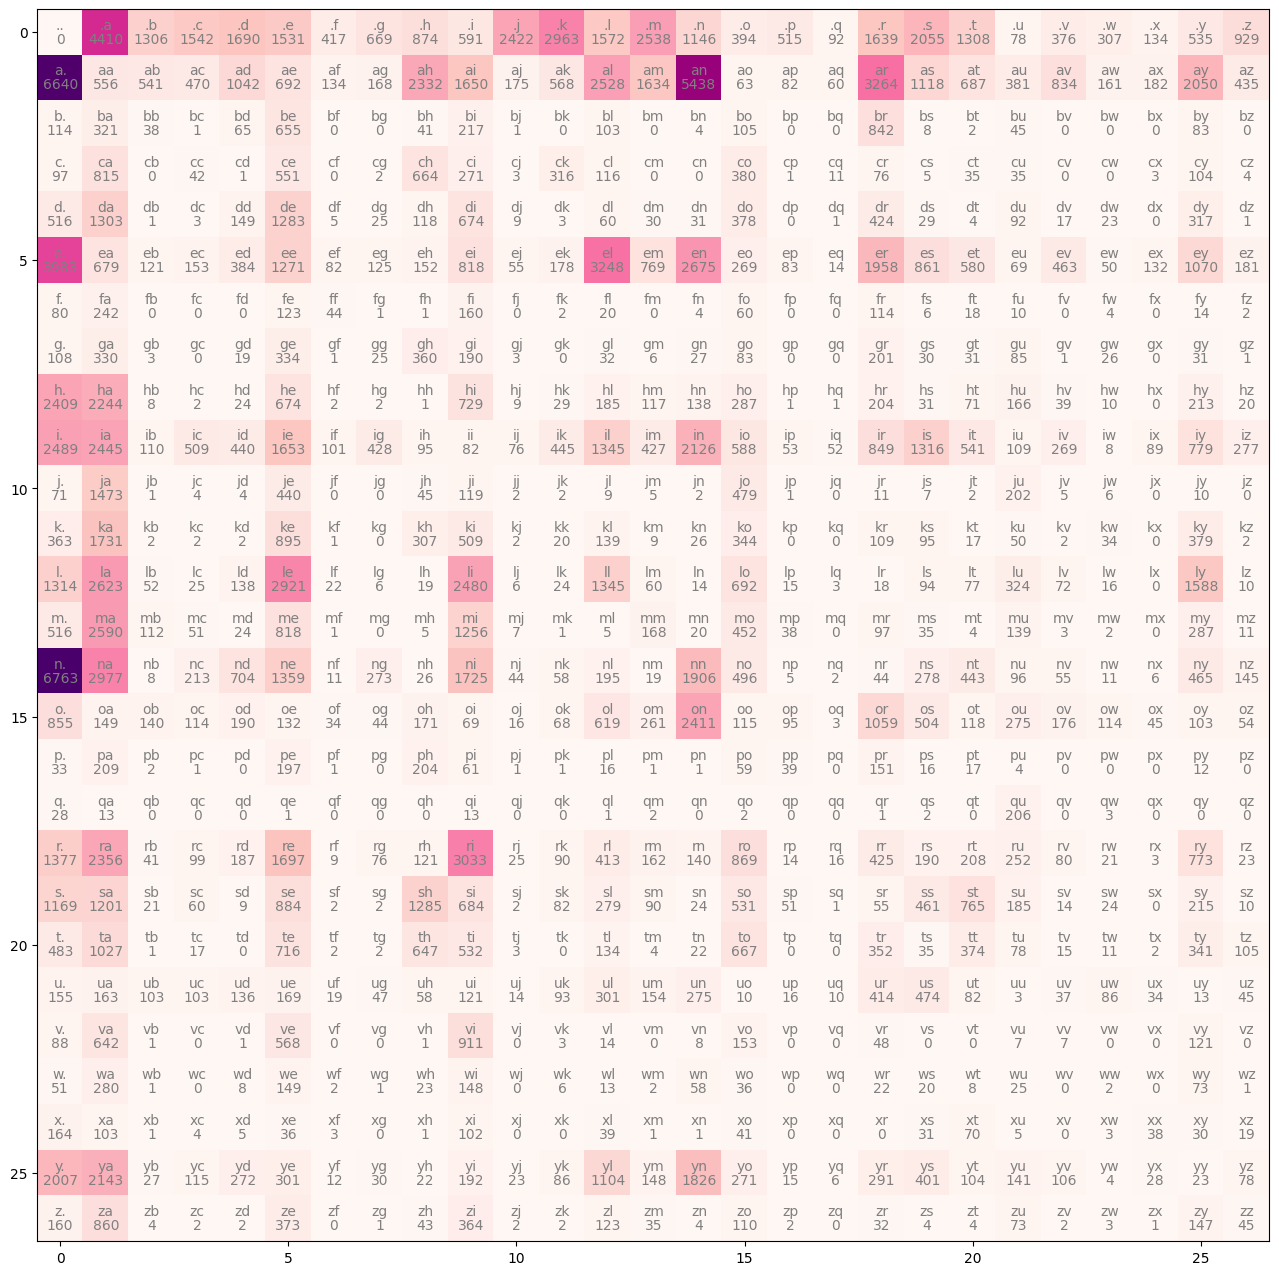

In [40]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(16,16))
plt.imshow(N,cmap='RdPu')
for i in range (27):
  for j in range (27):
    chstr=itos[i]+itos[j]
    plt.text(j,i,chstr,ha='center',va='bottom',color='gray')
    plt.text(j,i,N[i,j].item(),ha='center',va='top',color='gray')

In [21]:
p= N[0].float()
p=p/p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [16]:
g=torch.Generator().manual_seed(2147483647)
p=torch.rand(3,generator=g)
p=p/p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [18]:
torch.multinomial(p,num_samples=50,replacement=True,generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 2, 0, 0,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
        0, 2])

In [22]:
g=torch.Generator().manual_seed(2147483647)
ix=torch.multinomial(p,num_samples=1,replacement=True,generator=g).item()
itos[ix]

'c'

In [23]:
ix

3

karpathy took m and ix 13. it results from how pytorch version difference is realted to manual_seed number

In [26]:
g=torch.Generator().manual_seed(2147483647)

for i in range(10):
  out=[]
  ix=0
  while True:
    #p=N[ix].float()
    #p=p/p.sum()
    p=P[ix]
    #p=torch.ones(27)/27.0
    ix=torch.multinomial(p,num_samples=1,replacement=True,generator=g).item()
    out.append(itos[ix])
    if ix==0:
      break
  print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [32]:
P=(N+1).float()
P/=P.sum(1,keepdim=True)

Two dimensions are compatible if they're equal, or one of them is 1 (the 1 gets stretched)

In [33]:
log_likelihood=0.0
n=0

for w in words:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    prob= P[ix1,ix2]
    logprob=torch.log(prob)
    log_likelihood+=logprob
    n+=1
    #print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'{log_likelihood=}')
nll= -log_likelihood
print(f'{nll=}')
print(f'{nll/n:.4f}')

log_likelihood=tensor(-559951.5625)
nll=tensor(559951.5625)
2.4544


In [35]:
xs,ys =[],[]

for w in words[:1]:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    print(ch1,ch2)
    xs.append(ix1)
    ys.append(ix2)

xs=torch.tensor(xs)
ys=torch.tensor(ys)

. e
e m
m m
m a
a .


In [45]:
import torch.nn.functional as F
xenc= F.one_hot(xs, num_classes=27).float()
xenc


tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [47]:
xs

tensor([ 0,  5, 13, 13,  1])

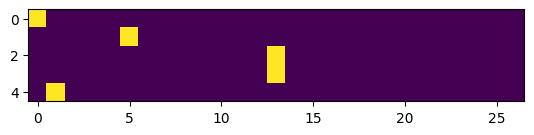

In [46]:
plt.imshow(xenc)

In [48]:
xenc.dtype

torch.float32

In [51]:
W=torch.randn((27,27))

In [52]:
(xenc@W).exp()

tensor([[ 1.2296,  0.3028,  0.8469,  0.3429,  1.9072,  1.5360,  0.7038,  1.5546,
          1.3860,  2.4804,  0.7033, 20.6965,  1.6148,  1.7341,  0.4040,  0.8134,
          2.1466,  1.1301,  5.2530,  4.0325,  0.3952,  4.6237,  0.4533,  0.3748,
         15.3712,  0.4157,  2.9822],
        [ 0.3982,  1.0801,  2.5683,  3.1668,  7.8073,  1.9778,  0.5629,  0.3244,
          0.6113,  1.3959,  0.1037,  1.1222,  0.5135,  0.1561,  1.7312,  0.9942,
          2.2585,  3.3574,  1.4379,  0.8748,  1.2103,  0.5019,  0.4015,  3.1982,
          1.1692,  1.3711,  2.0274],
        [ 0.7745,  0.3237,  0.8890,  0.0812,  1.9845,  3.0540,  3.8837,  2.1254,
          0.4096,  1.2721,  0.1858,  0.6165,  0.7440,  0.5295,  0.3547,  0.3365,
          0.2331,  1.8312,  0.4774,  0.7608,  2.3410,  1.4599,  1.1088,  0.5665,
          3.6316,  5.4918,  0.9483],
        [ 0.7745,  0.3237,  0.8890,  0.0812,  1.9845,  3.0540,  3.8837,  2.1254,
          0.4096,  1.2721,  0.1858,  0.6165,  0.7440,  0.5295,  0.3547,  0.3365

In [53]:
logits=xenc@W
counts=logits.exp()
probs=counts/counts.sum(1,keepdims=True)
probs

tensor([[0.0163, 0.0040, 0.0112, 0.0045, 0.0253, 0.0204, 0.0093, 0.0206, 0.0184,
         0.0329, 0.0093, 0.2744, 0.0214, 0.0230, 0.0054, 0.0108, 0.0285, 0.0150,
         0.0696, 0.0535, 0.0052, 0.0613, 0.0060, 0.0050, 0.2038, 0.0055, 0.0395],
        [0.0094, 0.0255, 0.0607, 0.0748, 0.1845, 0.0467, 0.0133, 0.0077, 0.0144,
         0.0330, 0.0025, 0.0265, 0.0121, 0.0037, 0.0409, 0.0235, 0.0534, 0.0793,
         0.0340, 0.0207, 0.0286, 0.0119, 0.0095, 0.0756, 0.0276, 0.0324, 0.0479],
        [0.0213, 0.0089, 0.0244, 0.0022, 0.0545, 0.0839, 0.1067, 0.0584, 0.0112,
         0.0349, 0.0051, 0.0169, 0.0204, 0.0145, 0.0097, 0.0092, 0.0064, 0.0503,
         0.0131, 0.0209, 0.0643, 0.0401, 0.0304, 0.0156, 0.0997, 0.1508, 0.0260],
        [0.0213, 0.0089, 0.0244, 0.0022, 0.0545, 0.0839, 0.1067, 0.0584, 0.0112,
         0.0349, 0.0051, 0.0169, 0.0204, 0.0145, 0.0097, 0.0092, 0.0064, 0.0503,
         0.0131, 0.0209, 0.0643, 0.0401, 0.0304, 0.0156, 0.0997, 0.1508, 0.0260],
        [0.0100, 0.0167,

In [65]:
g=torch.Generator().manual_seed(2147483647)
W = torch.randn((27,27),generator=g, requires_grad=True) #randn normal distribution

In [57]:
probs[0,5], probs[1,13], probs[2,13], probs [3,1], probs[4,0]

(tensor(0.0204),
 tensor(0.0037),
 tensor(0.0145),
 tensor(0.0089),
 tensor(0.0100))

In [59]:
torch.arange(5)

tensor([0, 1, 2, 3, 4])

In [61]:
loss=-probs[torch.arange(5),ys].log().mean()
loss

tensor(4.6109)

In [92]:
#forward pass
xenc= F.one_hot(xs, num_classes=27).float() #one hot encoding
logits=xenc@W
counts=logits.exp() #==N
probs=counts/counts.sum(1,keepdims=True) #softmax
loss=-probs[torch.arange(5),ys].log().mean()

In [93]:
print(loss.item())

3.669245958328247


In [94]:
#backward
W.grad=None
loss.backward()

In [95]:
W.data += -0.1*W.grad

Actual gradient descent and optimization part

In [101]:
xs, ys =[],[]
for w in words:
  chs=['.']+list(w)+['.']
  for ch1, ch2 in zip(chs,chs[1:]):
    ix1=stoi[ch1]
    ix2=stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs=torch.tensor(xs)
ys=torch.tensor(ys)
num= xs.nelement()
print("Number of examples: ",num)

g=torch.Generator().manual_seed(2147483647)
W=torch.randn((27,27),generator=g,requires_grad=True)

Number of examples:  228146


The first term (the data loss) says: "make good predictions — assign high probability to the correct next character." The second term says: "and keep the weights small while you're at it." Training tries to minimize the sum, so it has to balance both.prevent overfitting

In [106]:
#gradient descent
for k in range(100):
  #forward pass
  xenc= F.one_hot(xs, num_classes=27).float() #one hot encoding
  logits=xenc@W
  counts=logits.exp() #==N
  probs=counts/counts.sum(1,keepdims=True) #softmax
  loss=-probs[torch.arange(num),ys].log().mean() + 0.01*(W**2).mean()
  print(loss.item())

  #backward pass
  W.grad=None
  loss.backward()

  #update
  W.data += -50*W.grad

2.4855616092681885
2.485492706298828
2.485424518585205
2.4853579998016357
2.485292434692383
2.4852283000946045
2.485165596008301
2.4851038455963135
2.4850430488586426
2.484983444213867
2.4849255084991455
2.484867572784424
2.484811544418335
2.4847562313079834
2.484701633453369
2.4846487045288086
2.4845962524414062
2.484544515609741
2.48449444770813
2.4844446182250977
2.4843955039978027
2.4843478202819824
2.484300374984741
2.4842545986175537
2.484208583831787
2.484164237976074
2.4841198921203613
2.4840762615203857
2.4840340614318848
2.483992338180542
2.4839508533477783
2.483910322189331
2.483870506286621
2.4838314056396484
2.483792543411255
2.4837546348571777
2.483717441558838
2.483680486679077
2.483644485473633
2.4836087226867676
2.4835736751556396
2.48353910446167
2.4835050106048584
2.483471632003784
2.483438730239868
2.4834063053131104
2.4833741188049316
2.4833426475524902
2.483311891555786
2.483281135559082
2.483250856399536
2.4832215309143066
2.483191967010498
2.483163356781006
2.48

result for with coutning case was 2.4544, pretty close to gradient descent result


In [117]:
g= torch.Generator().manual_seed(2147483647)

for i in range (5):
  out=[]
  ix=0
  while True:
    #p=P[ix]

    xenc=F.one_hot(torch.tensor([ix]),num_classes=27).float()
    logits=xenc@W
    counts=logits.exp()
    p=counts/counts.sum(1,keepdims=True)

    ix=torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix==0:
      break
  print(''.join(out))

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x27 and 30x30)

after case: cexze.
momasurailezityha.
konimittain.
llayn.
ka.

before case : cexze.
momasurailezitynn.
konimittain.
llayn.
ka.

---------------------Turkish names----------

In [110]:
words = open('turkish_names.txt', 'r', encoding='utf-8').read().splitlines()

chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0                                  # '.' is the start/end token = 0
itos = {i: s for s, i in stoi.items()}        # reverse map

vocab_size = len(itos)
print(vocab_size)

30


In [122]:
min(len(w) for w in words), max(len(w) for w in words)

(2, 17)

In [124]:
for w in words:
    if len(w) == 17:
        print(w)

altıntamgantarkan
bilgeışbaratamgan
biligköngülsengün


In [129]:
import torch.nn.functional as F

# build the training set of bigrams
xs, ys = [], []
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        xs.append(stoi[ch1])
        ys.append(stoi[ch2])
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()

g = torch.Generator().manual_seed(2147483647)
W = torch.randn((vocab_size, vocab_size), generator=g, requires_grad=True)


4.0134100914001465
3.6078014373779297
3.344144582748413
3.17214298248291
3.0569024085998535
2.972651720046997
2.9078481197357178
2.8564982414245605
2.8148157596588135
2.780259370803833
2.751107692718506
2.7261743545532227
2.70462703704834
2.6858632564544678
2.66943359375
2.6549861431121826
2.642238140106201
2.6309521198272705
2.6209285259246826
2.6119930744171143
2.6039962768554688
2.596809148788452
2.590320348739624
2.5844361782073975
2.579076051712036
2.5741724967956543
2.5696685314178467
2.565516233444214
2.5616767406463623
2.558114767074585
2.554802417755127
2.551713466644287
2.548827886581421
2.546126365661621
2.5435924530029297
2.5412113666534424
2.538970708847046
2.536858320236206
2.5348639488220215
2.5329782962799072
2.5311925411224365
2.5294997692108154
2.5278918743133545
2.5263631343841553
2.5249080657958984
2.5235211849212646
2.522197723388672
2.5209336280822754
2.5197243690490723
2.5185673236846924
2.5174574851989746
2.5163938999176025
2.5153732299804688
2.5143918991088867


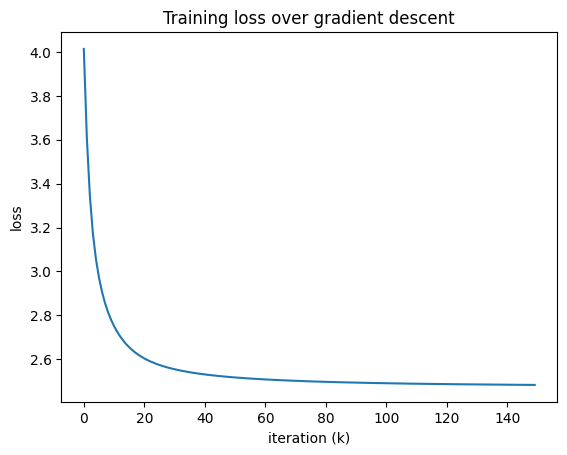

In [130]:
import matplotlib.pyplot as plt

losses=[]

#gradient descent
for k in range(150):
  #forward pass
  xenc= F.one_hot(xs, num_classes=vocab_size).float() #one hot encoding
  logits=xenc@W
  counts=logits.exp() #==N
  probs=counts/counts.sum(1,keepdims=True) #softmax
  loss=-probs[torch.arange(num),ys].log().mean() + 0.01*(W**2).mean()
  print(loss.item())
  losses.append(loss.item())
  #backward pass
  W.grad=None
  loss.backward()

  #update
  W.data += -50*W.grad

print(loss.item())

plt.plot(losses)
plt.xlabel('iteration (k)')
plt.ylabel('loss')
plt.title('Training loss over gradient descent')
plt.show()

In [132]:
g= torch.Generator().manual_seed(2147483647)

for i in range (30):
  out=[]
  ix=0
  while True:

    xenc=F.one_hot(torch.tensor([ix]),num_classes=vocab_size).float()
    logits=xenc@W
    counts=logits.exp()
    p=counts/counts.sum(1,keepdims=True)

    ix=torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix==0:
      break
  print(''.join(out))

unsu.
çoğmuslbör.
e.
çerdışhtmur.
baçulgüze.
tuin.
a.
turışbersa.
h.
at.
ürsayeç.
azmüyuturan.
ekadumı.
kemay.
ekar.
jdur.
aydum.
u.
ıy.
akç.
ikar.
kaydürbayunakı.
er.
ben.
ökiltuğaniş.
ka.
elışenetaykok.
talulmay.
tom.
yü.
